# 04 – Vom Ring zum Kästchen

**Ziel.** Der Auftraggeber hat je Parkfeld einen **Ring** gesetzt (einen Punkt). Das Netz lernt aber Flächen. Hier wird aus jedem Ring ein **Kästchen** (Rechteck), und jedes Feld bekommt drei Angaben: seine Klasse, seinen Grund und je Bild seine Kategorie.

**Warum.** Das Kästchen ist die Lösung, an der das Netz lernt und gemessen wird. Liegt es falsch, lernt das Netz Falsches. Darum wird hier zweimal geprüft: mit einer Rechnung (geht die Fläche auf?) und mit dem Auge (liegen die Kästchen auf den Feldern?).

| Angabe | Werte | Wozu |
| --- | --- | --- |
| Klasse | `eng`, `weit`, `einzeln` | bestimmt Breite und Tiefe des Kästchens (Notebook 03) |
| Grund | Strassenraum oder übriger Grund | nur Felder im Strassenraum werden mit amtlichen Daten verglichen (`01b`, Abschnitt 11, E2) |
| Kategorie je Bild | `sichtbar`, `verdeckt, belegt`, `verdeckt`, `unsicher`, `Streifen`, `einzeln`, `kein Parkfeld` | bestimmt den Wert im Lösungsblatt und in welcher Zeile ein Feld gezählt wird |

**Eingaben:** Ground Truth, `aufteilung.csv` (Notebook 02), `platzmasse.json` (Notebook 03), Bodenbedeckung (Notebook 00), Grundstücke der amtlichen Vermessung, das Luftbild vom Frühjahr 2021 (nur für die Abbildung in Abschnitt 6).
**Ausgaben:** `daten/verarbeitet/kaestchen.gpkg` (ein Kästchen je Feld), `daten/verarbeitet/strassenraum.gpkg` (Grundstücke im Strassenraum), Abbildung `04_kaestchen.png`.

In [1]:
import json                        # Einstellungen, Ground Truth und Platzmasse lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen
HAND = ROOT / "daten" / "ground_truth" / "ground_truth_hand.json"   # Ground Truth des Auftraggebers (wird nur gelesen)
BILD_2021 = ROH / "orthofoto" / "fruehjahr_2021"     # Luftbild Frühjahr 2021 (nur für die Abbildung in Abschnitt 6)

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen aus Notebook 00
CRS, SEED, GEBIET_NAME = EINST["CRS"], EINST["SEED"], EINST["GEBIET_NAME"]
MASSE = json.loads((VERARB / "platzmasse.json").read_text(encoding="utf-8"))    # Platzmasse aus Notebook 03
print("Platzmasse aus Notebook 03:", {klasse: MASSE[klasse] for klasse in ["eng", "weit"]})

import numpy as np                 # Rechnen
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
import rasterio                    # Luftbild lesen (für die Abbildung)
from rasterio.merge import merge   # Ausschnitt aus mehreren Bilddateien zusammensetzen
from shapely.geometry import box, Point            # Rechteck und Punkt
from shapely.affinity import rotate, translate     # Formen drehen und verschieben

Platzmasse aus Notebook 03: {'eng': {'breite_m': 2.5, 'tiefe_m': 5.0, 'flaeche_m2': 12.48}, 'weit': {'breite_m': 5.61, 'tiefe_m': 1.9, 'flaeche_m2': 10.66}}


## 1. Felder mit Klasse und Richtung lesen

**Schritt 1: zwei Dateien zusammenführen.** Die Ground Truth liefert Form, Herkunft und den Zustand je Bild. Notebook 03 hat zu jedem Ring seine Reihe bestimmt: Abstand, Richtung (`winkel`) und Klasse. `merge` hängt beides über die Kennung des Feldes zusammen.

Vorher: Felder der Ground Truth und Tabelle der Ringe → nachher: eine Tabelle mit allem.

In [2]:
erfasst = json.loads(HAND.read_text(encoding="utf-8"))             # einmal lesen; die Datei wird nicht verändert
KACHEL_M = erfasst["einstellungen"]["kachel_m"]                    # Seitenlänge eines Ausschnitts: 51,2 m
felder = pd.DataFrame(erfasst["felder"])[["id", "herkunft", "form", "zustand"]]
ringe = pd.read_csv(VERARB / "ringe.csv")                          # Reihe, Abstand, Winkel und Klasse je Ring (Notebook 03)
felder = ringe.merge(felder, on="id", how="left")                  # je Ring die Angaben der Ground Truth

ohne_ausschnitt = felder.gruppe.isna()                             # knapp neben einem Ausschnitt gesetzt
print(f"Gesetzte Felder: {len(felder)} → davon in keinem Ausschnitt: {int(ohne_ausschnitt.sum())} (werden weggelassen)")
felder = felder[~ohne_ausschnitt].reset_index(drop=True)
print(felder.klasse.value_counts().to_string())

Gesetzte Felder: 3278 → davon in keinem Ausschnitt: 9 (werden weggelassen)
klasse
eng        1743
weit       1430
einzeln      96


## 2. Das Kästchen

**Schritt 1: an einem Feld.** Ein Kästchen entsteht in drei Handgriffen:
1. ein Rechteck um den Nullpunkt: **Breite** entlang der Reihe, **Tiefe** quer dazu (`box`);
2. um den Winkel der Reihe drehen (`rotate`);
3. an die Stelle des Rings schieben (`translate`).

Die Breite ist der typische Abstand der Klasse, die Tiefe die Normtiefe (Notebook 03).

In [3]:
def kaestchen(x, y, winkel, klasse):
    # Rechteck mit der Breite und Tiefe der Klasse, entlang der Reihe gedreht, Mitte beim Ring
    breite, tiefe = MASSE[klasse]["breite_m"], MASSE[klasse]["tiefe_m"]
    rechteck = box(-breite / 2, -tiefe / 2, breite / 2, tiefe / 2)            # 1. Rechteck um den Nullpunkt
    gedreht = rotate(rechteck, winkel, origin=(0, 0), use_radians=True)      # 2. in die Richtung der Reihe drehen
    return translate(gedreht, x, y)                                          # 3. zum Ring schieben

beispiel = felder[felder.klasse == "eng"].iloc[0]                  # das erste Feld einer engen Reihe
form = kaestchen(beispiel.x, beispiel.y, beispiel.winkel, beispiel.klasse)
print(f"Ring bei ({beispiel.x:.1f}, {beispiel.y:.1f}), nächster Ring der Reihe in {beispiel.abstand_m:.2f} m, Winkel {np.degrees(beispiel.winkel):.0f}°")
print(f"Kästchen: Fläche {form.area:.2f} m² (erwartet {MASSE['eng']['flaeche_m2']} m²), Mitte ({form.centroid.x:.1f}, {form.centroid.y:.1f})")

Ring bei (2683305.2, 1247053.8), nächster Ring der Reihe in 2.92 m, Winkel 12°
Kästchen: Fläche 12.50 m² (erwartet 12.48 m²), Mitte (2683305.2, 1247053.8)


**Schritt 2: für alle Felder.** Die Schleife wiederholt Schritt 1. Ein **einzeln** stehendes Feld hat keinen Nachbarn, also keine Richtung. Ein Kästchen wäre dort geraten. Es bekommt stattdessen einen Kreis von 3 m um den Ring; diese Fläche wird später nicht bewertet (`01b`, Abschnitt 11, E4).

Vorher: Ringe mit Klasse und Richtung → nachher: eine Form je Feld (Kästchen oder Kreis).

In [4]:
formen = []                                                        # leere Sammelliste
for feld in felder.itertuples():
    if feld.klasse == "einzeln":
        formen.append(Point(feld.x, feld.y).buffer(3.0))           # Kreis von 3 m: nicht bewertete Fläche
    else:
        formen.append(kaestchen(feld.x, feld.y, feld.winkel, feld.klasse))
felder = gpd.GeoDataFrame(felder, geometry=formen, crs=CRS)
print(f"Vorher: {len(felder)} Ringe → nachher: {int((felder.klasse != 'einzeln').sum())} Kästchen und {int((felder.klasse == 'einzeln').sum())} Kreise")

Vorher: 3269 Ringe → nachher: 3173 Kästchen und 96 Kreise


## 3. Kategorie je Bild

**Worum es geht.** Der Auftraggeber hat für jedes Feld und jedes Bild einen Zustand gesetzt und dem Feld eine Form gegeben. Daraus folgt je Bild genau **eine** Kategorie. Die Regeln stehen in `01b` (8.2 W1 und W6, Abschnitt 9, 10.1, Abschnitt 11 E4) und werden hier der Reihe nach angewendet; die erste passende gilt.

| Reihenfolge | Bedingung | Kategorie | im Lösungsblatt | wird gezählt als |
| --- | --- | --- | --- | --- |
| 1 | Zustand `kein Parkfeld` | `kein Parkfeld` | 0 | – |
| 2 | Form `═` (Streifen) | `Streifen` | 255 | von Hand geschätzte Plätze, getrennt |
| 3 | Zustand `unsicher` | `unsicher` | 255 | nicht gezählt |
| 4 | Zustand `verdeckt`, und das Feld ist im anderen Bild sichtbar oder stammt aus der DAV | `verdeckt, belegt` | 255 | getrennt |
| 5 | Zustand `verdeckt`, ohne Beleg | `verdeckt` | 255 | nicht gezählt |
| 6 | Klasse `einzeln` | `einzeln` | 255 | getrennt |
| 7 | sonst (Zustand `sichtbar`) | `sichtbar` | 1 | **ja** |

Die Formen `✕` (Taxi, Polizei, Feld mit Kreuz) und `?` (Invalidenparkplatz) sind aufgemalte Einzelfelder und fallen unter Regel 7.

**Schritt 1: die Regeln als Funktion, an einem Bild.**

In [5]:
def kategorie(zustand, zustand_anderes_bild):
    # wendet die sieben Regeln der Tabelle der Reihe nach an; np.select nimmt die erste passende
    belegt = (zustand_anderes_bild == "sichtbar") | (felder.herkunft == "DAV")     # Beleg für ein verdecktes Feld
    bedingungen = [zustand == "kein Parkfeld", felder.form == "Streifen ohne Einzelfelder", zustand == "unsicher",
                   (zustand == "verdeckt") & belegt, zustand == "verdeckt", felder.klasse == "einzeln"]
    namen = ["kein Parkfeld", "Streifen", "unsicher", "verdeckt, belegt", "verdeckt", "einzeln"]
    return np.select(bedingungen, namen, default="sichtbar")

zustand_2021 = pd.Series([zustand["2021"] for zustand in felder.zustand])         # Zustand je Bild als Spalte
zustand_2024_25 = pd.Series([zustand["2024_25"] for zustand in felder.zustand])
felder["kat_2021"] = kategorie(zustand_2021, zustand_2024_25)                     # Bild Frühjahr 2021 (Versuch A)
felder["kat_2024_25"] = kategorie(zustand_2024_25, zustand_2021)                  # Bild Sommer 2024/25 (Versuch B)

pd.DataFrame({"Frühjahr 2021": felder.kat_2021.value_counts(), "Sommer 2024/25": felder.kat_2024_25.value_counts()}).fillna(0).astype(int)

,Frühjahr 2021,Sommer 2024/25
Streifen,208,200
einzeln,84,52
kein Parkfeld,43,118
sichtbar,2708,1833
unsicher,66,176
verdeckt,90,92
"verdeckt, belegt",70,798


## 4. Auf welchem Grund liegt das Feld?

**Worum es geht.** Die DAV führt nur öffentlich zugängliche Felder. Der Auftraggeber hat aber jedes aufgemalte Feld gesetzt, auch in Innenhöfen. Die Regel aus `01b` (10.3 und Abschnitt 11, E2): Ein Feld liegt im **Strassenraum**, wenn sein Grundstück mindestens zur Hälfte aus Strasse, Weg, Trottoir oder Verkehrsinsel besteht.

**Schritt 1: Grundstücke mit der Bodenbedeckung verschneiden.** Wie in Notebook 01, Abschnitt 14: `overlay` schneidet jedes Grundstück in Teilstücke je Bodenbedeckung; daraus folgt der Anteil Strassenraum je Grundstück. Wir nehmen alle Grundstücke, die einen Ausschnitt berühren, damit Notebook 09 dieselbe Tabelle auch für erkannte Flächen verwenden kann.

Vorher: Grundstücke und Bodenbedeckung → nachher: je Grundstück der Anteil Strassenraum.

In [6]:
bo = gpd.read_file(VERARB / f"bodenbedeckung_{GEBIET_NAME}.gpkg")[["art_txt", "geometry"]]              # Bodenbedeckung (Notebook 00)
grundstuecke = gpd.read_file(ROH / "vermessung/av_li_liegenschaft_a_kreis1.geojson").to_crs(CRS)[["nummer", "geometry"]]

aufteilung = pd.read_csv(VERARB / "aufteilung.csv")
erfasste_flaeche = gpd.GeoSeries([box(i * KACHEL_M, j * KACHEL_M, (i + 1) * KACHEL_M, (j + 1) * KACHEL_M)
                                  for i, j in zip(aufteilung.i, aufteilung.j)], crs=CRS).union_all()   # alle Ausschnitte als eine Fläche
grundstuecke = grundstuecke[grundstuecke.intersects(erfasste_flaeche)]                                # nur Grundstücke, die einen Ausschnitt berühren

stuecke = gpd.overlay(grundstuecke, bo, how="intersection", keep_geom_type=True)                      # Grundstück × Bodenbedeckung
stuecke["m2"] = stuecke.area
STRASSENRAUM = ["befestigt.Strasse_Weg.Strasse", "befestigt.Strasse_Weg.Velo_Fussweg", "befestigt.Trottoir",
                "befestigt.Verkehrsinsel", "humusiert.uebrige_humusierte.Verkehrsteilerflaeche"]
m2_strasse = stuecke[stuecke.art_txt.isin(STRASSENRAUM)].groupby("nummer").m2.sum()                   # Strassenraum je Grundstück
m2_alles = stuecke.groupby("nummer").m2.sum()                                                         # ganze Fläche je Grundstück
grundstuecke["anteil_strassenraum"] = grundstuecke.nummer.map(m2_strasse / m2_alles).fillna(0)        # ohne Strassenraum: Anteil 0
grundstuecke["strassenraum"] = grundstuecke.anteil_strassenraum >= 0.5
print(f"Grundstücke an den Ausschnitten: {len(grundstuecke)} → davon Strassenraum: {int(grundstuecke.strassenraum.sum())}")
grundstuecke[grundstuecke.strassenraum].to_file(VERARB / "strassenraum.gpkg", driver="GPKG")         # für Notebook 09

Grundstücke an den Ausschnitten: 2439 → davon Strassenraum: 425


**Schritt 2: je Feld nachschlagen.** `sjoin` hängt an jeden Ring das Grundstück, in dem er liegt.

Vorher: Felder → nachher: dieselben Felder mit der Angabe Strassenraum ja oder nein.

In [7]:
ringe = gpd.GeoDataFrame(felder[["id"]], geometry=gpd.points_from_xy(felder.x, felder.y), crs=CRS)    # die Ringe als Punkte
treffer = gpd.sjoin(ringe, grundstuecke[["strassenraum", "geometry"]], how="left", predicate="within")
treffer = treffer[~treffer.index.duplicated()]                     # liegt ein Ring genau auf einer Grenze, zählt er einmal
felder["strassenraum"] = treffer.strassenraum.fillna(False).astype(bool).values
print(f"Vorher: {len(felder)} Felder → nachher: {int(felder.strassenraum.sum())} im Strassenraum, {int((~felder.strassenraum).sum())} auf übrigem Grund")
pd.crosstab(felder.herkunft, felder.strassenraum.map({True: "Strassenraum", False: "übriger Grund"}), margins=True, margins_name="alle")

Vorher: 3269 Felder → nachher: 1938 im Strassenraum, 1331 auf übrigem Grund


strassenraum,Strassenraum,übriger Grund,alle
herkunft,,,
DAV,988,41,1029
neu,950,1290,2240
alle,1938,1331,3269


## 5. Prüfung mit einer Rechnung: Geht die Fläche auf?

**Worum es geht.** Später wird gezählt: Anzahl = Fläche ÷ Platzfläche. Das stimmt nur, wenn die Kästchen einer Reihe aneinanderstossen, ohne sich stark zu überlappen. Wir prüfen das in den **Lernblöcken** an den sichtbaren Feldern des Bildes 2021:

- `union_all()` verschmilzt alle Kästchen einer Klasse zu einer Fläche (Überlappungen zählen nur einmal);
- diese Fläche, geteilt durch die Platzfläche, sollte die Zahl der Felder ergeben.

Ein Verhältnis von 1,00 heisst: Die Formel geht genau auf. Unter 1 heisst: Kästchen überlappen sich, die Formel zählt zu wenig.

In [8]:
pruefung = felder[(felder.gruppe == "lernen") & (felder.kat_2021 == "sichtbar")]      # sichtbare Felder der Lernblöcke
zeilen = []
for klasse in ["eng", "weit"]:
    auswahl = pruefung[pruefung.klasse == klasse]
    flaeche = auswahl.geometry.union_all().area                    # verschmolzene Fläche aller Kästchen der Klasse
    aus_flaeche = flaeche / MASSE[klasse]["flaeche_m2"]            # so viele Plätze ergibt die Formel
    zeilen.append({"klasse": klasse, "felder": len(auswahl), "flaeche_m2": round(flaeche), "aus_flaeche": round(aus_flaeche, 1),
                   "verhaeltnis": round(aus_flaeche / len(auswahl), 3)})
pd.DataFrame(zeilen).set_index("klasse")

,felder,flaeche_m2,aus_flaeche,verhaeltnis
klasse,,,,
eng,941,11400,913.4,0.971
weit,714,7448,698.7,0.979


## 6. Prüfung mit dem Auge: Liegen die Kästchen auf den Feldern?

Wir ziehen je vier Felder aus engen und aus weiten Reihen (fester Seed, höchstens eines je Ausschnitt) und zeichnen die Kästchen ihrer Umgebung auf das Bild vom Frühjahr 2021. Blau: enge Reihe. Orange: weite Reihe. Grau gestrichelt: Fläche, die nicht bewertet wird (verdeckt, unsicher, Streifen, einzeln).

In [9]:
bilddateien = [rasterio.open(pfad) for pfad in sorted(BILD_2021.glob("*.tif"))]     # die Dateien des Luftbilds, einmal geöffnet

def zeige_luftbild(ax, x, y, halbe_seite=11):
    # Zeichnet das Luftbild Frühjahr 2021 um den Punkt (x, y); die Achsen sind Landeskoordinaten in Metern
    links, unten, rechts, oben = x - halbe_seite, y - halbe_seite, x + halbe_seite, y + halbe_seite
    bild, _ = merge(bilddateien, bounds=(links, unten, rechts, oben), res=0.05, indexes=[1, 2, 3])   # Rot, Grün, Blau bei 5 cm
    ax.imshow(bild.transpose(1, 2, 0), extent=[links, rechts, unten, oben])      # (Kanäle, Zeilen, Spalten) -> (Zeilen, Spalten, Kanäle)
    ax.set_xticks([]); ax.set_yticks([])                                         # keine Achsenbeschriftung

print(len(bilddateien), "Bilddateien des Luftbilds Frühjahr 2021 geöffnet")

6 Bilddateien des Luftbilds Frühjahr 2021 geöffnet


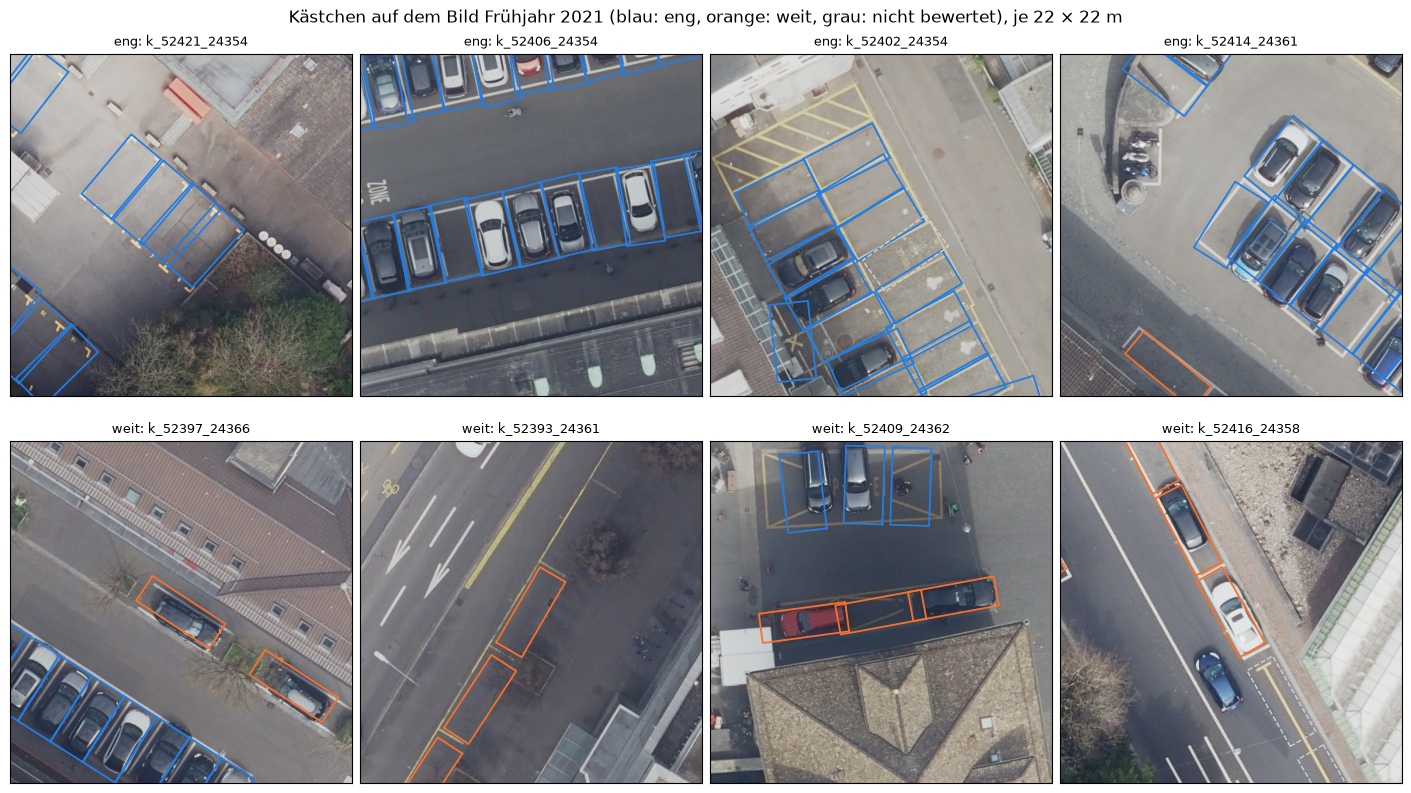

In [10]:
FARBE = {"eng": "#257de0", "weit": "#f47230"}                          # Projektfarben wie in Notebook 01
fig, achsen = plt.subplots(2, 4, figsize=(14, 8), layout="constrained")
for zeile, klasse in enumerate(["eng", "weit"]):
    auswahl = felder[(felder.klasse == klasse) & (felder.kat_2021 == "sichtbar")].groupby("kachel").sample(1, random_state=SEED)
    auswahl = auswahl.sample(4, random_state=SEED)                     # vier Beispiele
    for ax, feld in zip(achsen[zeile], auswahl.itertuples()):
        zeige_luftbild(ax, feld.x, feld.y)                             # 22 × 22 m um das Feld
        nahe = felder[(abs(felder.x - feld.x) < 13) & (abs(felder.y - feld.y) < 13)]      # Felder der Umgebung
        bewertet = nahe[nahe.kat_2021 == "sichtbar"]
        for umriss in bewertet.itertuples():                           # jedes bewertete Kästchen in der Farbe seiner Klasse
            ax.plot(*umriss.geometry.exterior.xy, color=FARBE[umriss.klasse], linewidth=1.3)
        for umriss in nahe[~nahe.kat_2021.isin(["sichtbar", "kein Parkfeld"])].itertuples():   # nicht bewertete Flächen
            ax.plot(*umriss.geometry.exterior.xy, color="lightgrey", linewidth=1.0, linestyle="--")
        ax.set_xlim(feld.x - 11, feld.x + 11); ax.set_ylim(feld.y - 11, feld.y + 11)
        ax.set_title(f"{klasse}: {feld.kachel}", fontsize=9)
fig.suptitle("Kästchen auf dem Bild Frühjahr 2021 (blau: eng, orange: weit, grau: nicht bewertet), je 22 × 22 m")
fig.savefig(ABB / "04_kaestchen.png", dpi=110, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Liegen die blauen Kästchen quer über den Feldern, in denen Autos nebeneinander stehen, und die orangen längs über den Feldern am Strassenrand, stimmen Klasse und Richtung. Ein Kästchen, das quer zur Reihe liegt, wäre ein Fehler der Richtung.

## 7. Speichern

In [11]:
spalten = ["id", "kachel", "gruppe", "herkunft", "form", "klasse", "strassenraum", "kat_2021", "kat_2024_25", "x", "y", "geometry"]
felder[spalten].to_file(VERARB / "kaestchen.gpkg", driver="GPKG")
print(f"gespeichert: daten/verarbeitet/kaestchen.gpkg mit {len(felder)} Feldern")
pd.crosstab(felder.gruppe, felder.kat_2021, margins=True, margins_name="alle")

gespeichert: daten/verarbeitet/kaestchen.gpkg mit 3269 Feldern


kat_2021,Streifen,einzeln,kein Parkfeld,sichtbar,unsicher,verdeckt,"verdeckt, belegt",alle
gruppe,,,,,,,,
lernen,124,54,31,1655,34,57,45,2000
testen,58,13,8,708,13,27,19,846
validieren,26,17,4,345,19,6,6,423
alle,208,84,43,2708,66,90,70,3269


## Was wir gesehen haben

- Aus jedem Ring wurde ein Kästchen mit den Massen aus Notebook 03, ausgerichtet an seiner Reihe. Einzeln stehende Felder bekommen kein Kästchen und werden getrennt ausgewiesen.
- Jedes Feld hat je Bild genau eine Kategorie (Tabelle in Abschnitt 3) und die Angabe, ob es im Strassenraum liegt (Abschnitt 4).
- Die Rechnung in Abschnitt 5 zeigt, wie gut "Fläche ÷ Platzfläche" die Zahl der Felder trifft; das Verhältnis steht dort.

## Wie es weitergeht

Notebook 05 malt die Kästchen auf ein Pixelraster (das Lösungsblatt), schneidet die Luftbilder in Kacheln und prüft die Zählformel noch einmal am fertigen Lösungsblatt.